# Introduction

In this project, you will build a neural network of your own design to evaluate the MNIST dataset.

Some of the benchmark results on MNIST include can be found on [on Yann LeCun's page](http://yann.lecun.com/exdb/mnist/) and include:

88% [Lecun et al., 1998](http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf)
95.3% [Lecun et al., 1998](http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf)
99.65% [Ciresan et al., 2011](http://people.idsia.ch/~juergen/ijcai2011.pdf)

MNIST is a great dataset for sanity checking your models, since the accuracy levels achieved by large large convolutional neural networks and small linear models are both quite high. This makes it important to be familiar with the data

## Import

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd
import random

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

## Load the dataset

Specify your transforms as a list if you intend to. The transforms module is already loaded as transforms.

MNIST is fortunately included in the torchvision module. Then, you can create your dataset using the MNIST object from torchvision.datasets [the documentation is available here](https://pytorch.org/vision/stable/datasets.html#mnist). Make sure to specify download=True

Once your dataset is created, you will also need to define a Dataloader from the torch.utils.data module for both the train and the test set.

In [3]:
# Defining the transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, ), (0.5, ))
])

mnist_dataset = torchvision.datasets.MNIST(root="data", train=True, download=False, transform=transform)

# Defining the size of train, validation, and test sets
train_size = int(0.6 * len(mnist_dataset))
val_size = int(0.2 * len(mnist_dataset))
test_size = len(mnist_dataset) - train_size - val_size

# Splitting the MNIST dataset
train_dataset, val_dataset, test_dataset = random_split(mnist_dataset, [train_size, val_size, test_size])

# Create test set and define test dataloader 
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128)
test_loader = DataLoader(test_dataset, batch_size=128)

### Justify your preprocessing

Normalization is a process of scaling the input data to a common range. It is a common practice to normalize the input data before feeding to the neural network. The primary reason for normalization is to ensure that the input features are on similar scale, which helps to stabilize the gradient step, allowing us to use larger learning rates or help model converge faster for a given learning rate.

If the input variable are combined linearly, as in MLP, then it is rarely strictly necessary to standardize the inputs, at least in theory. However, there are a variety of practical reasons why standardizing can make training faster and reduces the chances of getting stuck in local optima. 

I chose ToTensor() to convert each image into a PyTorch tensor, with pixel values scaled from 0-255 to 0-1.
Normalize((0.5,), (0.5,)) then shifts and scales those value to approximately -1 to 1. This gives the model consistent, centered inputs that are generally easier totrain on. The single mean and standard deviation are approriate for grayscale images.

## Explore the dataset


In [4]:
## This cell contains function for showing  5 images from a dataloader - DO NOT CHANGE THE CONTENT
def show5(img_loader):
    dataiter = iter(img_loader)
    
    batch = next(dataiter)
    labels = batch[1][0:5]
    images = batch[0][0:5]
    for i in range(5):
        print(int(labels[i].detach()))
        
        image = images[i].numpy()
        plt.imshow(image.T.squeeze().T)
        plt.show()
    

4


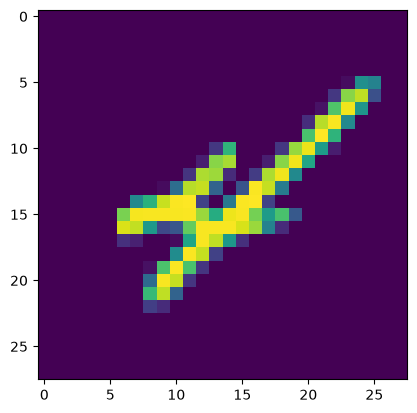

6


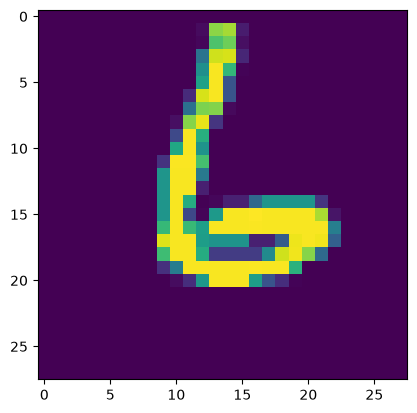

8


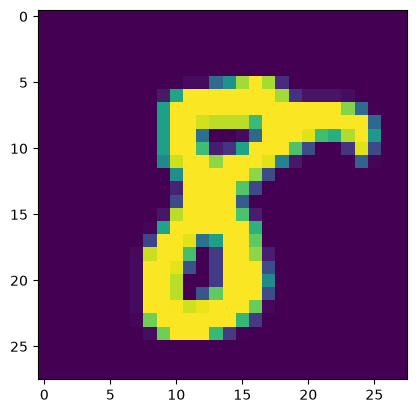

2


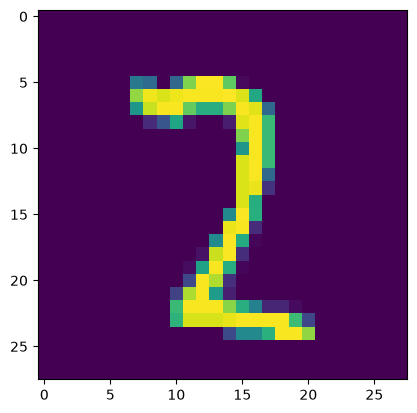

3


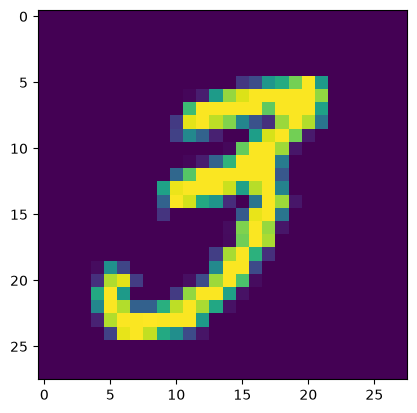

In [5]:
# Explore data
show5(train_loader)

## Build your Neural network



In [6]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.activation = F.relu
        self.dropout = nn.Dropout(p=0.5)
        self.layer1 = nn.Linear(28*28*1, 256)
        self.layer2 = nn.Linear(256, 128)
        self.layer3 = nn.Linear(128, 64)
        self.layer4 = nn.Linear(64, 10)
        
    def forward(self, x):
        x = torch.flatten(x, 1)
        x = self.activation(self.layer1(x))
        x = self.dropout(x)
        x = self.activation(self.layer2(x))
        x = self.dropout(x)
        x = self.activation(self.layer3(x))
        x = self.layer4(x)
        return x

In [7]:
net = Net()

optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.99, weight_decay=0.001)
criterion = nn.CrossEntropyLoss()


## Running your Neural network

Use whatever method you like to train your neural network, and ensure your record the average loss at each epoch. Do not forget to use torch.device() and the .to() method for both your model and your data if you are using GPU!

If you want to print your loss during each epoch, you can use the enumerate function and print the loss after a set number of batches. 250 batches works well for most people!

In [8]:
# Move the model to the GPU if available
device =  torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
net.to(device)


Net(
  (dropout): Dropout(p=0.5, inplace=False)
  (layer1): Linear(in_features=784, out_features=256, bias=True)
  (layer2): Linear(in_features=256, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=64, bias=True)
  (layer4): Linear(in_features=64, out_features=10, bias=True)
)

In [9]:
# number of epochs 
num_epochs = 20

# creating lists for loss history
train_loss_history = list()
val_loss_history = list()

best_val_loss = float("inf")

# The start of the training
for epoch in range(num_epochs):
    # putting the model in training mode
    net.train()
    # setting the epoch loss and number of correct predictions to 0
    train_loss = 0.0
    train_correct = 0
    total_predictions = 0
    
    for i, data in enumerate(train_loader):
        inputs, labels = data
        
        if torch.cuda.is_available():
            inputs, labels = inputs.to(device), labels.to(device)
            
        optimizer.zero_grad()
        
        outputs = net(inputs)
        
        loss = criterion(outputs, labels)
        
        loss.backward()
        
        optimizer.step()
        
        _, preds = torch.max(outputs.data, 1)
        total_predictions += labels.size(0)
        train_correct += (preds == labels).sum().item()
        train_loss += loss.item()
        
    print(f"Epoch {epoch + 1} training accuracy: {train_correct/total_predictions * 100:.2f} training loss: {train_loss/len(train_loader):.5f}")
    train_loss_history.append(train_loss/len(train_loader))
    
    # The validation phase
    net.eval()
    val_loss = 0.0
    val_correct = 0
    total_predictions = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            if torch.cuda.is_available():
                inputs, labels = inputs.to(device), labels.to(device)
                
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs.data, 1)
            total_predictions += labels.size(0)
            val_correct += (preds==labels).sum().item()
            val_loss += loss.item()
    
    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = val_correct / total_predictions *100
    
    print(f"Epoch {epoch + 1} validation accuracy: {val_accuracy:.2f}% validation loss: {avg_val_loss:.5f}")
    val_loss_history.append(avg_val_loss)
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch + 1
        torch.save(net.state_dict(), "best_model.pth")


Epoch 1 training accuracy: 58.93 training loss: 1.17864
Epoch 1 validation accuracy: 87.70% validation loss: 0.45839
Epoch 2 training accuracy: 75.46 training loss: 0.79426
Epoch 2 validation accuracy: 88.81% validation loss: 0.43515
Epoch 3 training accuracy: 77.32 training loss: 0.77125
Epoch 3 validation accuracy: 90.20% validation loss: 0.40558
Epoch 4 training accuracy: 74.71 training loss: 0.82116
Epoch 4 validation accuracy: 87.44% validation loss: 0.45870
Epoch 5 training accuracy: 74.56 training loss: 0.83517
Epoch 5 validation accuracy: 88.29% validation loss: 0.51969
Epoch 6 training accuracy: 74.55 training loss: 0.83946
Epoch 6 validation accuracy: 87.97% validation loss: 0.53132
Epoch 7 training accuracy: 74.09 training loss: 0.84194
Epoch 7 validation accuracy: 88.62% validation loss: 0.44478
Epoch 8 training accuracy: 75.33 training loss: 0.80964
Epoch 8 validation accuracy: 85.41% validation loss: 0.53725
Epoch 9 training accuracy: 73.72 training loss: 0.83505
Epoch 9 

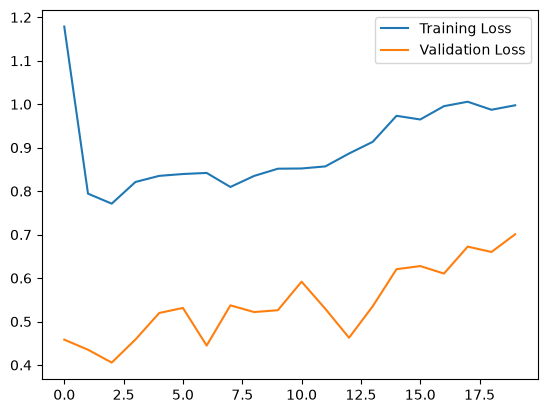

In [10]:
plt.plot(train_loss_history, label="Training Loss")
plt.plot(val_loss_history, label="Validation Loss")
plt.legend()
plt.show()

## Testing your model

Using the previously created DataLoader for the test set, compute the percentage of correct predictions using the highest probability prediction.

If your accuracy is over 90%, great work, but see if you can push a bit further! If your accuracy is under 90%, you will need to make improvements. Go back and check your model architecture, loss function, and optimizer to make sure they are appropriate for an image classification task.

In [11]:
net.load_state_dict(torch.load("best_model.pth", map_location=device))
net.eval()

print(f"Best epoch: {best_epoch}, validation loss: {best_val_loss:.5f}")

correct_predictions = 0
total_predictions = 0

for inputs, labels in test_loader:
    if torch.cuda.is_available():
        inputs, labels = inputs.to(device), labels.to(device)
    
    outputs = net(inputs)
    _, preds = torch.max(outputs.data, 1)
    total_predictions += labels.size(0)
    correct_predictions += (preds==labels).sum().item()
    
    accuracy = (correct_predictions / total_predictions) * 100

print(f"Accuracy: {accuracy:.2f}%")

Best epoch: 3, validation loss: 0.40558
Accuracy: 89.60%


## Improving your model

Once your model is done training, try tweaking your hyperparameters and training again below to improve your accuracy on the test set!



In [12]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.activation = F.relu
        self.layer1 = nn.Linear(28*28*1, 256)
        self.layer2 = nn.Linear(256, 128)
        self.layer3 = nn.Linear(128, 64)
        self.layer4 = nn.Linear(64, 10)
        
    def forward(self, x):
        x = torch.flatten(x, 1)
        x = self.activation(self.layer1(x))
        x = self.activation(self.layer2(x))
        x = self.activation(self.layer3(x))
        x = self.layer4(x)
        return x

In [13]:
# exprimenting with the opitimzer
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.99, weight_decay=0.001)


In [14]:
# number of epochs 
num_epochs = 20

# creating lists for loss history
train_loss_history = list()
val_loss_history = list()

# the start of the training
for epoch in range(num_epochs):
    # putting the model in training mode
    net.train()
    # setting the epoch loss and number of correct prediction to zero
    train_loss = 0.0
    train_correct = 0
    
    for i, data in enumerate(train_loader):
        inputs, labels = data
    
        if torch.cuda.is_available():
            inputs, labels = inputs.to(device), labels.to(device)
            
        optimizer.zero_grad()
        
        outputs = net(inputs)
        
        loss = criterion(outputs, labels)
        
        loss.backward()
        
        optimizer.step()
        
        _, preds = torch.max(outputs.data, 1)
        train_correct = (preds==labels).sum().item()
        train_loss += loss.item()
    
    print(f"Epoch {epoch+1} training accuracy: {train_correct/len(train_loader.dataset) * 100:.2f}% training loss: {train_loss/len(train_loader):.5f}")
    train_loss_history.append(train_loss/len(train_loader))
    
    # The validation phase
    val_loss = 0.0
    val_correct = 0
    net.eval()
    for inputs, labels in val_loader:
        if torch.cuda.is_available():
            inputs, labels = inputs.to(device), labels.to(device)
            
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        
        _, preds = torch.max(outputs.data, 1)
        val_correct += (preds==labels).sum().item()
        val_loss += loss.item()
    print(f"Epoch {epoch+1} validation accuracy: {val_correct/len(val_loader.dataset) * 100:.2f}% validation loss: {val_loss/len(val_loader):.5f}")
    val_loss_history.append(val_loss/len(val_loader))

Epoch 1 training accuracy: 0.07% training loss: 0.60356
Epoch 1 validation accuracy: 91.21% validation loss: 0.35210
Epoch 2 training accuracy: 0.07% training loss: 0.54493
Epoch 2 validation accuracy: 91.93% validation loss: 0.32264
Epoch 3 training accuracy: 0.08% training loss: 0.52006
Epoch 3 validation accuracy: 91.87% validation loss: 0.31355
Epoch 4 training accuracy: 0.08% training loss: 0.50924
Epoch 4 validation accuracy: 92.15% validation loss: 0.30301
Epoch 5 training accuracy: 0.08% training loss: 0.48827
Epoch 5 validation accuracy: 92.38% validation loss: 0.29917
Epoch 6 training accuracy: 0.07% training loss: 0.47480
Epoch 6 validation accuracy: 92.47% validation loss: 0.29208
Epoch 7 training accuracy: 0.08% training loss: 0.46371
Epoch 7 validation accuracy: 92.64% validation loss: 0.28086
Epoch 8 training accuracy: 0.07% training loss: 0.45670
Epoch 8 validation accuracy: 92.93% validation loss: 0.27266
Epoch 9 training accuracy: 0.08% training loss: 0.46172
Epoch 9 

## Final accuracy after tweaking the model

In [15]:
correct_predictions = 0
total_predictions = 0

for inputs, labels in test_loader:
    if torch.cuda.is_available():
        inputs, labels = inputs.to(device), labels.to(device)
        
    outputs = net(inputs)
    _, preds = torch.max(outputs.data, 1)
    total_predictions += labels.size(0)
    correct_predictions += (preds == labels).sum().item()
    accuracy = (correct_predictions / total_predictions) * 100
    
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 93.16%


In [16]:
# exprimenting with the opitimzer
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.99, weight_decay=0.001)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

In [17]:
# number of epochs 
num_epochs = 20

# creating lists for loss history
train_loss_history = list()
val_loss_history = list()

# the start of the training
for epoch in range(num_epochs):
    # putting the model in training mode
    net.train()
    # setting the epoch loss and number of correct prediction to zero
    train_loss = 0.0
    train_correct = 0
    
    for i, data in enumerate(train_loader):
        inputs, labels = data
    
        if torch.cuda.is_available():
            inputs, labels = inputs.to(device), labels.to(device)
            
        optimizer.zero_grad()
        
        outputs = net(inputs)
        
        loss = criterion(outputs, labels)
        
        loss.backward()
        
        optimizer.step()
        
        _, preds = torch.max(outputs.data, 1)
        train_correct = (preds==labels).sum().item()
        train_loss += loss.item()
    
    print(f"Epoch {epoch+1} training accuracy: {train_correct/len(train_loader.dataset) * 100:.2f}% training loss: {train_loss/len(train_loader):.5f}")
    train_loss_history.append(train_loss/len(train_loader))
    
    # The validation phase
    val_loss = 0.0
    val_correct = 0
    net.eval()
    for inputs, labels in val_loader:
        if torch.cuda.is_available():
            inputs, labels = inputs.to(device), labels.to(device)
            
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        
        _, preds = torch.max(outputs.data, 1)
        val_correct += (preds==labels).sum().item()
        val_loss += loss.item()
    print(f"Epoch {epoch+1} validation accuracy: {val_correct/len(val_loader.dataset) * 100:.2f}% validation loss: {val_loss/len(val_loader):.5f}")
    val_loss_history.append(val_loss/len(val_loader))

Epoch 1 training accuracy: 0.07% training loss: 0.39094
Epoch 1 validation accuracy: 93.33% validation loss: 0.24333
Epoch 2 training accuracy: 0.09% training loss: 0.40066
Epoch 2 validation accuracy: 93.70% validation loss: 0.22992
Epoch 3 training accuracy: 0.08% training loss: 0.38372
Epoch 3 validation accuracy: 93.67% validation loss: 0.21832
Epoch 4 training accuracy: 0.08% training loss: 0.38036
Epoch 4 validation accuracy: 93.89% validation loss: 0.22370
Epoch 5 training accuracy: 0.08% training loss: 0.38439
Epoch 5 validation accuracy: 93.77% validation loss: 0.22130
Epoch 6 training accuracy: 0.08% training loss: 0.38453
Epoch 6 validation accuracy: 93.96% validation loss: 0.21825
Epoch 7 training accuracy: 0.08% training loss: 0.37506
Epoch 7 validation accuracy: 93.82% validation loss: 0.21926
Epoch 8 training accuracy: 0.07% training loss: 0.36660
Epoch 8 validation accuracy: 93.79% validation loss: 0.22183
Epoch 9 training accuracy: 0.07% training loss: 0.37993
Epoch 9 

In [18]:
correct_predictions = 0
total_predictions = 0

for inputs, labels in test_loader:
    if torch.cuda.is_available():
        inputs, labels = inputs.to(device), labels.to(device)
        
    outputs = net(inputs)
    _, preds = torch.max(outputs.data, 1)
    total_predictions += labels.size(0)
    correct_predictions += (preds == labels).sum().item()
    accuracy = (correct_predictions / total_predictions) * 100
    
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 93.73%


# CNN Model


In [23]:
class ImprovedNN(nn.Module):
    def __init__(self):
        super(ImprovedNN, self).__init__()
        
        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        
        # Max pooling layer
        self.pool = nn.MaxPool2d(2, 2)
        
        # Fully connected layers
        self.fc1 = nn.Linear(64*7*7, 512)
        self.fc2 = nn.Linear(512, 10)
        
        # Dropout layer for regularization
        self.dropout = nn.Dropout(0.5)
    
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        
        x = x.view(-1, 64*7*7)
        
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ImprovedNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2)

Epoch [1/10], Batch [250], Loss: 0.0757
Epoch [1/10] completed. Average Loss: 0.0079
Epoch [2/10], Batch [250], Loss: 0.0539
Epoch [2/10] completed. Average Loss: 0.0061
Epoch [3/10], Batch [250], Loss: 0.0419
Epoch [3/10] completed. Average Loss: 0.0051
Epoch [4/10], Batch [250], Loss: 0.0321
Epoch [4/10] completed. Average Loss: 0.0044
Epoch [5/10], Batch [250], Loss: 0.0273
Epoch [5/10] completed. Average Loss: 0.0043
Epoch [6/10], Batch [250], Loss: 0.0245
Epoch [6/10] completed. Average Loss: 0.0025
Epoch [7/10], Batch [250], Loss: 0.0197
Epoch [7/10] completed. Average Loss: 0.0024
Epoch [8/10], Batch [250], Loss: 0.0178
Epoch [8/10] completed. Average Loss: 0.0020
Epoch [9/10], Batch [250], Loss: 0.0132
Epoch [9/10] completed. Average Loss: 0.0021
Epoch [10/10], Batch [250], Loss: 0.0125
Epoch [10/10] completed. Average Loss: 0.0035


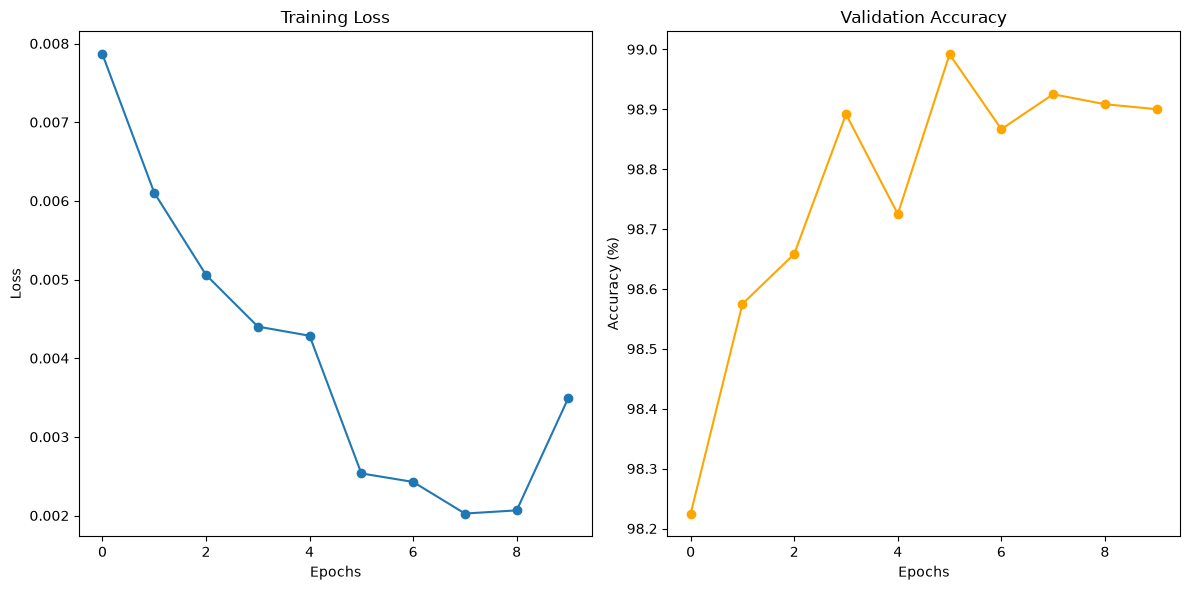

In [27]:
epochs = 10
batch_size = 64

train_losses = []
val_accuracies = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for i, (inputs, labels) in enumerate(train_loader, 0):
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs)
        
        loss = criterion(outputs, labels)
        
        loss.backward()
        
        optimizer.step()
        
        running_loss += loss.item()
        
        if i % 250 == 249:
            print(f"Epoch [{epoch+1}/{epochs}], Batch [{i+1}], Loss: {running_loss / 250:.4f}")
            running_loss = 0.0
    
    # Print the average loss for the epoch
    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)
    
    # Validation phase: evaluate on the test set
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted==labels).sum().item()
            
    val_accuracy = 100 * correct / total
    val_accuracies.append(val_accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] completed. Average Loss: {epoch_loss:.4f}")
    
    scheduler.step(epoch_loss)
    
plt.figure(figsize=(12, 6))

# Plot Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(epochs), train_losses, marker='o', label='Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss')

# Plot Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(epochs), val_accuracies, marker='o', label='Validation Accuracy', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Validation Accuracy')

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

In [29]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        outputs = model(inputs)
        
        _, predicted = torch.max(outputs, 1)
        
        total += labels.size(0)
        correct += (predicted==labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}")

Test Accuracy: 98.90


## Saving your model

Using torch.save, save your model for future loading.


In [ ]:
torch.save(net.state_dict(), "saved_model.pth")

## Implementing sanity checking



In [ ]:
# Assuming your model class is called Net
net = Net()

# Load the saved model
model_path = "saved_model.pth"
checkpoint = torch.load(model_path)

# Check if the 'model_state_dict' key is present in the checkpoint
if 'model_state_dict' in checkpoint:
    net.load_state_dict(checkpoint['model_state_dict'])
    print('Model loaded successfully.')
else:
    # If the key is not present, try loading the entire state dictionary
    net.load_state_dict(checkpoint)
    print('Model loaded successfully (full state dictionary).')
    
# If you also saved optimizer state, you can load it as well
if 'optimizer_state_dict' in checkpoint:
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    
# If you saved other information such as training epochs or loss history, you can load them too
# For example, if you saved the number of epochs
if 'epoch' in checkpoint:
    epoch = checkpoint['epoch']
    
# Move the model to the appropriate device (CPU or GPU)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
net.to(device)
net.eval()

Model loaded successfully (full state dictionary).


Net(
  (layer1): Linear(in_features=784, out_features=256, bias=True)
  (layer2): Linear(in_features=256, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=64, bias=True)
  (layer4): Linear(in_features=64, out_features=10, bias=True)
)

## Visualizing the predictions (actual vs predicted)

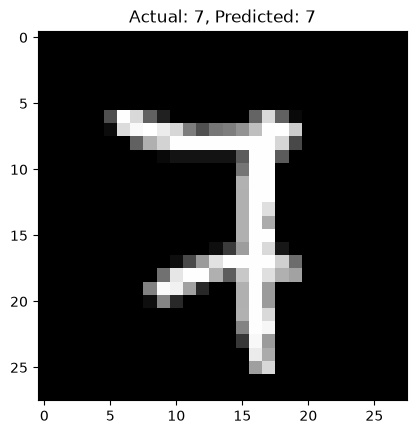

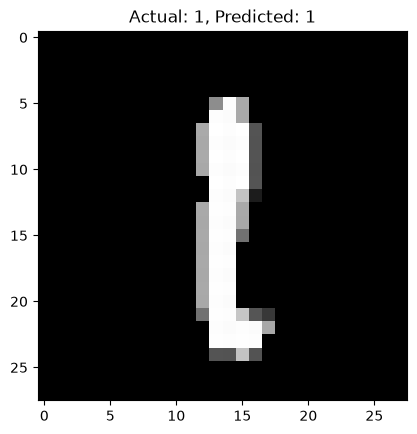

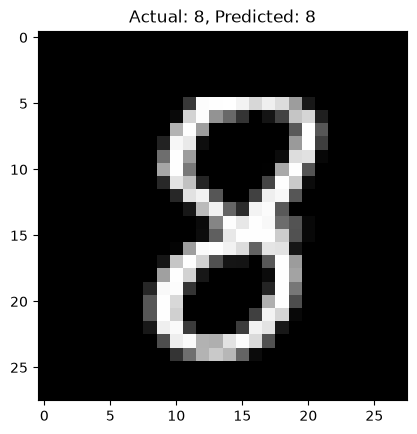

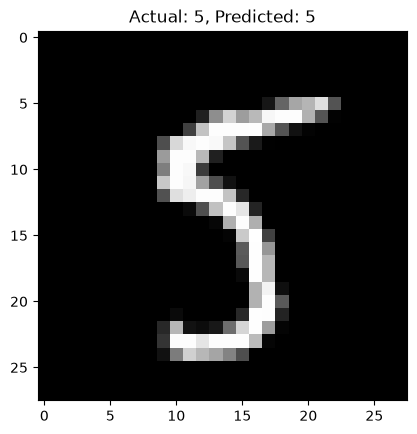

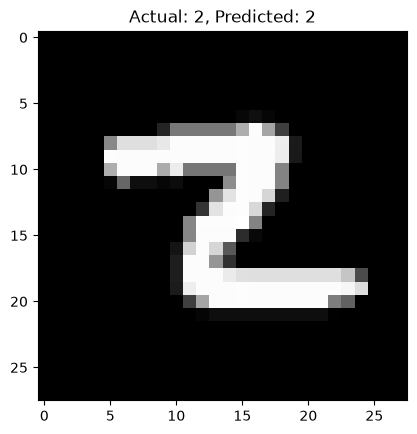

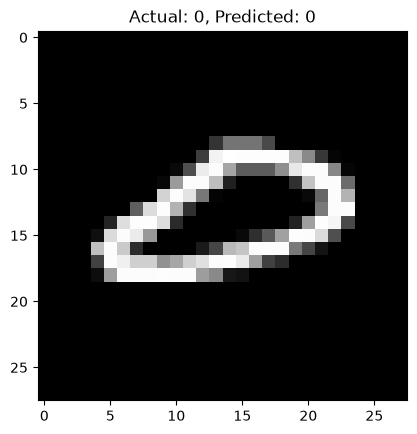

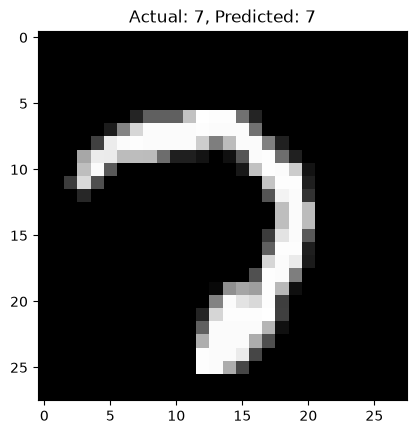

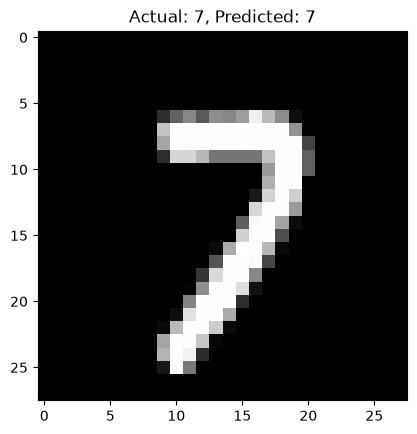

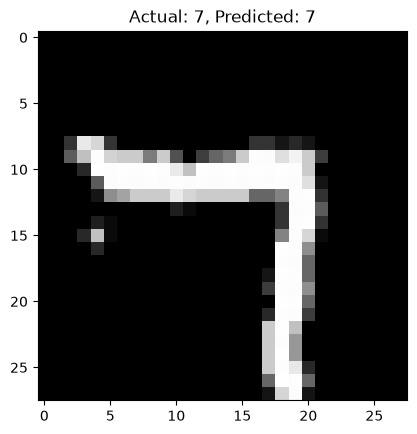

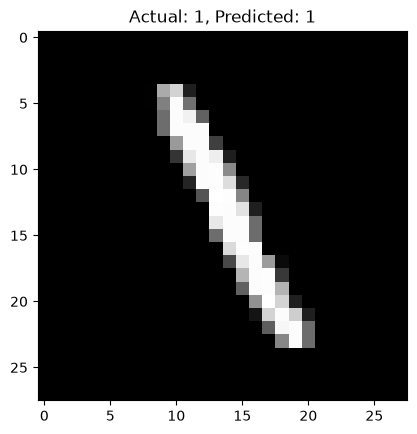

In [ ]:
def visualize_results(model, dataloader, device):
    model.eval()
    
    # Get the total number samples in the dataset
    total_samples = len(dataloader.dataset)
    
    # Randomly select 10 indices
    random_indices = random.sample(range(total_samples), 10)
    
    with torch.no_grad():
        for idx in random_indices:
            inputs, labels = dataloader.dataset[idx]
            inputs, labels = inputs.unsqueeze(0).to(device), torch.tensor([labels]).to(device)
            
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            # Convert tensors to Numpy arrays
            inputs = inputs.cpu().numpy()
            labels = labels.cpu().numpy()
            preds =  preds.cpu().numpy()
            
            # Display the sample
            plt.imshow(np.squeeze(inputs), cmap='gray')
            plt.title(f"Actual: {labels.item()}, Predicted: {preds[0]}")
            plt.show()

# Call the function with the model and the test dataloader
visualize_results(net, test_loader, device)
  
    

## Confusion matrix

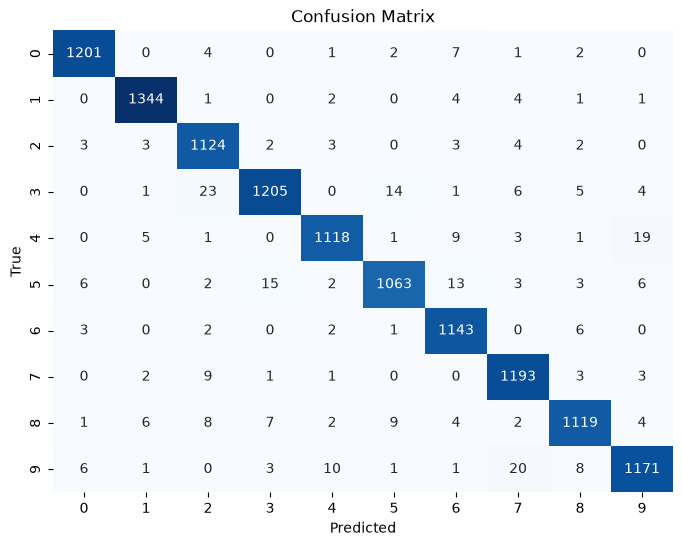

In [ ]:
net = net.to(device)
net.eval()

all_preds = []
all_labels = []

for inputs, labels in test_loader:
    if torch.cuda.is_available():
        inputs, labels = inputs.to(device), labels.to(device)
        
    outputs = net(inputs)
    _, preds = torch.max(outputs.data, 1)
    
    total_predictions += labels.size(0)
    correct_predictions += (preds==labels).sum().item()
    
    # Append predictions and labels for confusion matrix
    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())
    
# Create a confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

    